# SD 1.5 LCM-LoRA Consistency Distillation: v2 (rank 64, mixed dataset)

## 1. Overview

LCM-LoRA consistency distillation on Stable Diffusion 1.5, run on a free Colab **T4**.
Teacher: SD 1.5, 50-step DDIM, guidance 7.5. Student: the same UNet plus a LoRA adapter, evaluated at 1, 2 and 4 steps with `LCMScheduler` at guidance 1.0.

### What changes from v1

| Item | v1 | v2 |
|---|---|---|
| LoRA rank / alpha | 16 / 16 | **64 / 64** |
| Training steps | 3000 | **1500** (first v2 run; can be extended later) |
| Dataset | 10k Flickr30k images | **10k mix: 7k `jackyhate/text-to-image-2M` + 3k Flickr30k** |
| Checkpoint folder | `lcm_checkpoints` | **`lcm_checkpoints_r64`** (v1 stays untouched) |
| Checkpoint size | about 200 MB | about 800 MB (includes optimizer state) |
| Learning rate, loss, CFG range, accumulation | 1e-4, pseudo-Huber, w in [5, 15], 4 | unchanged |

Rank, dataset and step count all differ from v1, so a v2 improvement cannot be credited to any single one of them.
Validation losses are **not** comparable between v1 and v2 (different validation split). Compare with the CLIP benchmark in Section 20.

v1 reference (step 3000, rank 16, same 20 prompts and seeds as Section 20):

| Setup | CLIP matched | Mean time (s) | Speedup |
|---|---|---|---|
| Teacher 50-step | 32.72 | 8.756 | 1.0x |
| Student 1-step | 30.19 | 0.396 | 22.1x |
| Student 2-step | 32.30 | 0.502 | 17.4x |
| Student 4-step | 31.97 | 0.778 | 11.3x |

With 20 prompts and one seed each, differences below about 1 CLIP point are noise.

### Run order
1. Sections 2 to 5: environment, config, model loading (T4 runtime). Use **Run cell** one by one, not Run all.
2. Section 6: unpacks `mix_10k.tar` from Drive into `/content/mix_prepared`.
3. Sections 7 to 15: building blocks, student, unit tests, optimizer.
4. Section 16: set `MODE = "pilot"`, run the control cell and the loop cell, then the pilot check. After that set `MODE = "train"` and run the same two cells. After a disconnect, rerun Sections 2 to 15 and then the same two cells; training resumes from the newest checkpoint.
5. Sections 17 to 20: checkpoints, validation, image grid, CLIP benchmark.

## 2. Environment Setup

In [1]:
import platform
import torch

print("Python:", platform.python_version())
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    props = torch.cuda.get_device_properties(0)
    print("GPU:", props.name)
    print("Total GPU memory (GB):", round(props.total_memory / 1024**3, 2))
    print("CUDA capability:", f"{props.major}.{props.minor}")
    print("CUDA version (torch build):", torch.version.cuda)
else:
    print("WARNING: No GPU detected. In Colab: Runtime -> Change runtime type -> Hardware accelerator -> GPU (T4/L4/A100).")

Python: 3.13.16
PyTorch: 2.14.1+cu130
CUDA available: True
GPU: Tesla T4
Total GPU memory (GB): 14.56
CUDA capability: 7.5
CUDA version (torch build): 13.0


In [2]:
import torch; x = torch.randn(1024, 1024, device="cuda", dtype=torch.float16); print((x @ x).float().abs().mean().item())

25.52022933959961


In [3]:
# Mount Google Drive so checkpoints (cfg.CHECKPOINT_DIR) survive a Colab session reset.
# Skip this if you'd rather keep checkpoints ephemeral on the local Colab VM at /content/...
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [4]:
# Install compatible supporting libraries without replacing Colab's preinstalled PyTorch/CUDA build.
# If pip changes an already-imported package, restart the notebook session before continuing.
!pip install -q "diffusers>=0.35,<0.43" "transformers>=4.45,<5" "accelerate>=1,<2" "peft>=0.13,<1" "safetensors>=0.4" "datasets>=2,<5" ftfy sentencepiece

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.31.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio-client 2.7.2 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.


In [5]:
!pip uninstall -y torchao   # Colab's torchao breaks PEFT; remove it before PEFT is imported

Found existing installation: torchao 0.10.0
Uninstalling torchao-0.10.0:
  Successfully uninstalled torchao-0.10.0


In [6]:
import diffusers, transformers, accelerate, peft
print("Diffusers:", diffusers.__version__)
print("Transformers:", transformers.__version__)
print("Accelerate:", accelerate.__version__)
print("PEFT:", peft.__version__)

Diffusers: 0.39.0
Transformers: 4.57.6
Accelerate: 1.15.0
PEFT: 0.21.2


In [7]:
def gpu_memory_report(label=""):
    """GPU name, total/allocated/reserved/peak-allocated VRAM. Call at key points, not just in training."""
    if not torch.cuda.is_available():
        print(f"[{label}] No CUDA device.")
        return
    name = torch.cuda.get_device_properties(0).name
    total = torch.cuda.get_device_properties(0).total_memory / 1024**3
    alloc = torch.cuda.memory_allocated() / 1024**3
    reserved = torch.cuda.memory_reserved() / 1024**3
    peak = torch.cuda.max_memory_allocated() / 1024**3
    print(f"[{label}] GPU={name} total={total:.2f}GB alloc={alloc:.2f}GB reserved={reserved:.2f}GB peak={peak:.2f}GB")

gpu_memory_report("startup")

[startup] GPU=Tesla T4 total=14.56GB alloc=0.01GB reserved=0.04GB peak=0.02GB


## 3. Configuration

Single source of truth for every hyperparameter. **v2 changes** are marked `# v2` in the next cell: rank 64, alpha 64, checkpoint folder `lcm_checkpoints_r64`, dataset path `/content/mix_prepared`, 1500 target steps.

**Precision policy:** frozen backbones (teacher UNet, the student's frozen base weights, VAE, text encoder) are FP16; trainable LoRA parameters are FP32; forward passes run under `torch.autocast("cuda", dtype=torch.float16)`; the loss is computed in FP32; backward and step use `torch.amp.GradScaler`. This is a deliberate departure from the official script (which keeps the trainable UNet in FP32 on multi-GPU A100s), made so training fits on a T4. The objective itself is unchanged.

In [8]:
import os
from dataclasses import dataclass
from typing import Optional

@dataclass
class Config:
    # ---- Model ----
    MODEL_ID: str = "stable-diffusion-v1-5/stable-diffusion-v1-5"
    PREDICTION_TYPE_EXPECTED: str = "epsilon"

    # ---- Dataset ----
    DATASET_PATH: Optional[str] = "/content/mix_prepared"   # v2: 7k text-to-image-2M + 3k Flickr30k, built on CPU runtime
    DATASET_KIND: str = "auto"                  # "auto" | "hf_disk" | "image_caption_csv"
    VAL_FRACTION: float = 0.02
    IMAGE_SIZE: int = 512
    MIN_DATASET_SIZE: int = 2                    # need >=2 samples for a train/val split

    # ---- LCM / distillation ----
    NUM_DDIM_TIMESTEPS: int = 50
    NUM_TRAIN_TIMESTEPS: int = 1000
    LOSS_TYPE: str = "huber"                     # "huber" | "l2" (official default: huber, huber_c=0.001)
    HUBER_C: float = 0.001
    SIGMA_DATA: float = 0.5
    TIMESTEP_SCALING: float = 10.0                # see scalings_for_boundary_conditions, Section 9
    W_MIN: float = 5.0
    W_MAX: float = 15.0

    # ---- LoRA ----
    LORA_RANK: int = 64                           # v2 (v1: 16)
    LORA_ALPHA: int = 64                          # v2 (v1: 16)
    LORA_TARGET_MODULES: tuple = (
        "to_q", "to_k", "to_v", "to_out.0",
        "proj_in", "proj_out",
        "ff.net.0.proj", "ff.net.2",
        "conv1", "conv2", "conv_shortcut",
        "downsamplers.0.conv", "upsamplers.0.conv",
        "time_emb_proj",
    )

    # ---- Precision ----
    AUTOCAST_DTYPE: object = None                 # set to torch.float16 just below, after torch is imported

    # ---- Training ----
    MAX_TRAIN_STEPS: int = 1500                   # v2 first run (overridden by the Section 16 control cell)
    LEARNING_RATE: float = 1e-4
    LR_WARMUP_STEPS: int = 100
    TRAIN_BATCH_SIZE: int = 1
    GRADIENT_ACCUMULATION_STEPS: int = 4
    MAX_GRAD_NORM: float = 1.0
    RANDOM_SEED: int = 42
    GRADIENT_CHECKPOINTING: bool = True

    # ---- Logging / checkpointing ----
    CHECKPOINT_INTERVAL: int = 500
    VALIDATION_INTERVAL: int = 500
    LOG_INTERVAL: int = 10
    CHECKPOINT_DIR: str = "/content/drive/MyDrive/lcm_checkpoints_r64"  # v2: separate folder so v1 is never overwritten

In [9]:
import torch

cfg = Config()
cfg.AUTOCAST_DTYPE = torch.float16   # torch isn't importable yet when the dataclass body above is defined

os.makedirs(cfg.CHECKPOINT_DIR, exist_ok=True)
print("Configuration loaded.")
print(f"LoRA rank={cfg.LORA_RANK} alpha={cfg.LORA_ALPHA} targets={len(cfg.LORA_TARGET_MODULES)} patterns")
print(f"Precision: frozen weights FP16, LoRA params FP32, autocast dtype={cfg.AUTOCAST_DTYPE}")
print(f"DATASET_PATH = {cfg.DATASET_PATH!r}  ")

Configuration loaded.
LoRA rank=64 alpha=64 targets=14 patterns
Precision: frozen weights FP16, LoRA params FP32, autocast dtype=torch.float16
DATASET_PATH = '/content/mix_prepared'  


## 4. Imports and Reproducibility

In [10]:
import random
import copy
import csv
import time
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

def set_seed(seed: int):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

def get_rng_state():
    """Python/NumPy/Torch-CPU/Torch-CUDA RNG states, for checkpoint reproducibility."""
    return {
        "python": random.getstate(),
        "numpy": np.random.get_state(),
        "torch_cpu": torch.random.get_rng_state(),
        "torch_cuda": torch.cuda.get_rng_state_all() if torch.cuda.is_available() else None,
    }

def set_rng_state(state):
    random.setstate(state["python"])
    np.random.set_state(state["numpy"])
    torch.random.set_rng_state(state["torch_cpu"])
    if state["torch_cuda"] is not None and torch.cuda.is_available():
        torch.cuda.set_rng_state_all(state["torch_cuda"])

set_seed(cfg.RANDOM_SEED)
print("Global seed set to", cfg.RANDOM_SEED)

Global seed set to 42


## 5. Model Loading

Four frozen components: teacher UNet, VAE, text encoder, tokenizer. All loaded once in FP16 and
`requires_grad_(False)`. The student (Section 12) is a separate deep copy, created exactly once, never
recreated after the optimizer exists.

In [11]:
from diffusers import StableDiffusionPipeline, DDPMScheduler, DDIMScheduler

pipe = StableDiffusionPipeline.from_pretrained(
    cfg.MODEL_ID, torch_dtype=torch.float16, safety_checker=None,
)

tokenizer = pipe.tokenizer
text_encoder = pipe.text_encoder.to("cuda").eval()
vae = pipe.vae.to("cuda").eval()
teacher_unet = pipe.unet.to("cuda").eval()

for m in (text_encoder, vae, teacher_unet):
    m.requires_grad_(False)

noise_scheduler = DDPMScheduler.from_pretrained(cfg.MODEL_ID, subfolder="scheduler")
# The teacher baseline and the distillation solver must use the DDIM schedule, not the
# Stable Diffusion pipeline's default PNDM scheduler.
pipe.scheduler = DDIMScheduler.from_config(noise_scheduler.config)

assert noise_scheduler.config.prediction_type == cfg.PREDICTION_TYPE_EXPECTED, (
    f"This notebook's math assumes prediction_type='{cfg.PREDICTION_TYPE_EXPECTED}', got "
    f"'{noise_scheduler.config.prediction_type}'. Stopping rather than silently mishandling it."
)
assert noise_scheduler.config.num_train_timesteps == cfg.NUM_TRAIN_TIMESTEPS

print("Teacher UNet, VAE, text encoder, tokenizer, DDPMScheduler loaded and frozen.")
print("Teacher evaluation scheduler:", type(pipe.scheduler).__name__)
print("Prediction type:", noise_scheduler.config.prediction_type,
      "| num_train_timesteps:", noise_scheduler.config.num_train_timesteps)
gpu_memory_report("after model loading")

Flax classes are deprecated and will be removed in Diffusers v0.40.0. We recommend migrating to PyTorch classes or pinning your version of Diffusers.
Flax classes are deprecated and will be removed in Diffusers v0.40.0. We recommend migrating to PyTorch classes or pinning your version of Diffusers.
/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


model_index.json:   0%|          | 0.00/541 [00:00<?, ?B/s]

Fetching 13 files:   0%|          | 0/13 [00:00<?, ?it/s]

special_tokens_map.json:   0%|          | 0.00/472 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/617 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

... (8 outputs left out)

unet/diffusion_pytorch_model.safetensors:   0%|          | 0.00/3.44G [00:00<?, ?B/s]

Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

You have disabled the safety checker for <class 'diffusers.pipelines.stable_diffusion.pipeline_stable_diffusion.StableDiffusionPipeline'> by passing `safety_checker=None`. Ensure that you abide to the conditions of the Stable Diffusion license and do not expose unfiltered results in services or applications open to the public. Both the diffusers team and Hugging Face strongly recommend to keep the safety filter enabled in all public facing circumstances, disabling it only for use-cases that involve analyzing network behavior or auditing its results. For more information, please have a look at https://github.com/huggingface/diffusers/pull/254 .


Teacher UNet, VAE, text encoder, tokenizer, DDPMScheduler loaded and frozen.
Teacher evaluation scheduler: DDIMScheduler
Prediction type: epsilon | num_train_timesteps: 1000
[after model loading] GPU=Tesla T4 total=14.56GB alloc=2.02GB reserved=2.07GB peak=2.02GB


In [12]:
print("Teacher UNet trainable params:", sum(p.numel() for p in teacher_unet.parameters() if p.requires_grad))
print("VAE trainable params:", sum(p.numel() for p in vae.parameters() if p.requires_grad))
print("Text encoder trainable params:", sum(p.numel() for p in text_encoder.parameters() if p.requires_grad))

Teacher UNet trainable params: 0
VAE trainable params: 0
Text encoder trainable params: 0


## 6. Dataset Preparation

The v2 dataset was built beforehand on a CPU runtime and stored on Drive as `mix_10k.tar` (about 930 MB): 7,000 images from `jackyhate/text-to-image-2M` (MIT licence, recaptioned 512x512) and 3,000 from `nlphuji/flickr30k`, one random caption each.

Layout the loader expects: `<root>/captions.csv` with columns `file_name`, `caption`, plus `<root>/images/`.
Corrupt images and empty captions are skipped with a logged count, images are converted to RGB, resized and centre-cropped to 512, and normalised to `[-1, 1]`.
Captions longer than 77 tokens are cut off by the CLIP tokenizer, which is normal for the long text-to-image-2M captions.

In [13]:
import os, tarfile
TAR_PATH = "/content/drive/MyDrive/mix_10k.tar"
if not os.path.exists(f"{cfg.DATASET_PATH}/captions.csv"):
    assert os.path.exists(TAR_PATH), f"{TAR_PATH} not found. Mount Drive and check the file name."
    with tarfile.open(TAR_PATH) as t:
        t.extractall("/content")
print("DATASET_PATH =", cfg.DATASET_PATH)
print("captions.csv exists:", os.path.exists(f"{cfg.DATASET_PATH}/captions.csv"))
print("images count:", len(os.listdir(f"{cfg.DATASET_PATH}/images")))   # expect 10000

/tmp/ipykernel_467/2335692504.py:6: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  t.extractall("/content")


DATASET_PATH = /content/mix_prepared
captions.csv exists: True
images count: 10000


In [14]:
if not cfg.DATASET_PATH:
    raise ValueError(
        "cfg.DATASET_PATH is not set. Point it at your dataset in Section 3 "
        "(e.g. '/content/drive/MyDrive/my-image-caption-dataset' after mounting Drive, "
        "or '/content/my-image-caption-dataset' if uploaded directly to the Colab VM). "
        "This notebook will not guess a path."
    )
if not os.path.exists(cfg.DATASET_PATH):
    raise FileNotFoundError(f"cfg.DATASET_PATH={cfg.DATASET_PATH!r} does not exist.")
print("Dataset path OK:", cfg.DATASET_PATH)

Dataset path OK: /content/mix_prepared


In [15]:
from torch.utils.data import Dataset, DataLoader, random_split
import torchvision.transforms as T

def _detect_dataset_kind(path):
    if cfg.DATASET_KIND != "auto":
        return cfg.DATASET_KIND
    if os.path.exists(os.path.join(path, "dataset_info.json")):
        return "hf_disk"
    if os.path.exists(os.path.join(path, "captions.csv")):
        return "image_caption_csv"
    raise ValueError(
        f"Could not auto-detect dataset layout under {path!r}. Expected a `datasets.save_to_disk` "
        "directory (dataset_info.json) or captions.csv + images/. Set cfg.DATASET_KIND explicitly."
    )

_image_transform = T.Compose([
    T.Resize(cfg.IMAGE_SIZE, interpolation=T.InterpolationMode.BILINEAR),
    T.CenterCrop(cfg.IMAGE_SIZE),
    T.ToTensor(),
    T.Normalize([0.5], [0.5]),  # [0,1] -> [-1,1], matches the VAE's expected input range
])

class ImageCaptionCSVDataset(Dataset):
    """Skips rows with a missing/empty caption or an unreadable image file at load time, logging how
    many were skipped. `valid_indices` is the final usable row list."""
    def __init__(self, root, transform):
        self.root = root
        self.transform = transform
        with open(os.path.join(root, "captions.csv"), newline="", encoding="utf-8") as f:
            reader = csv.DictReader(f)
            required = {"file_name", "caption"}
            found = set(reader.fieldnames or [])
            missing = required - found
            if missing:
                raise ValueError(f"captions.csv is missing required columns: {sorted(missing)}")
            rows = list(reader)
        if not rows:
            raise ValueError(f"captions.csv under {root!r} has no rows.")

        self.rows, skipped_caption, skipped_image = [], 0, 0
        for r in rows:
            caption = (r.get("caption") or "").strip()
            file_name = (r.get("file_name") or "").strip()
            if not caption:
                skipped_caption += 1
                continue
            if not file_name:
                skipped_image += 1
                continue
            img_path = os.path.join(root, "images", file_name)
            try:
                with Image.open(img_path) as im:
                    im.verify()
            except Exception:
                skipped_image += 1
                continue
            self.rows.append(r)

        print(f"ImageCaptionCSVDataset: {len(rows)} rows -> {len(self.rows)} usable "
              f"(skipped {skipped_caption} missing captions, {skipped_image} unreadable images).")
        if len(rows) > 0 and len(self.rows) < 0.5 * len(rows):
            print("WARNING: more than half the rows were skipped — check captions.csv / images/ for a systemic issue.")
        if not self.rows:
            raise ValueError("No usable (image, caption) pairs remain after filtering.")

    def __len__(self):
        return len(self.rows)

    def __getitem__(self, idx):
        row = self.rows[idx]
        img = Image.open(os.path.join(self.root, "images", row["file_name"])).convert("RGB")
        return {"pixel_values": self.transform(img), "caption": row["caption"]}


class HFDiskDataset(Dataset):
    def __init__(self, hf_dataset, transform):
        self.ds = hf_dataset
        self.transform = transform
        self.caption_col = "text" if "text" in hf_dataset.column_names else "caption"
        if self.caption_col not in hf_dataset.column_names:
            raise ValueError("HF dataset needs a 'text' or 'caption' column.")
        if "image" not in hf_dataset.column_names:
            raise ValueError("HF dataset needs an 'image' column.")
        self.valid_indices = []
        skipped = 0
        for i in range(len(self.ds)):
            try:
                row = self.ds[i]
                caption = (row[self.caption_col] or "").strip()
                image = row["image"]
                if not caption or image is None:
                    skipped += 1
                    continue
                image.convert("RGB")  # force lazy image decode now, not mid-training
                self.valid_indices.append(i)
            except Exception:
                skipped += 1
        print(f"HFDiskDataset: {len(self.ds)} rows -> {len(self.valid_indices)} usable "
              f"(skipped {skipped} missing-caption/unreadable-image rows).")
        if not self.valid_indices:
            raise ValueError("No usable image-caption pairs remain in the HF dataset.")

    def __len__(self):
        return len(self.valid_indices)

    def __getitem__(self, idx):
        row = self.ds[self.valid_indices[idx]]
        caption = (row[self.caption_col] or "").strip()
        return {"pixel_values": self.transform(row["image"].convert("RGB")), "caption": caption}


def build_dataset():
    kind = _detect_dataset_kind(cfg.DATASET_PATH)
    if kind == "hf_disk":
        from datasets import load_from_disk
        return HFDiskDataset(load_from_disk(cfg.DATASET_PATH), _image_transform)
    elif kind == "image_caption_csv":
        return ImageCaptionCSVDataset(cfg.DATASET_PATH, _image_transform)
    raise ValueError(f"Unsupported DATASET_KIND: {kind}")

full_dataset = build_dataset()
if len(full_dataset) < cfg.MIN_DATASET_SIZE:
    raise ValueError(
        f"Dataset has only {len(full_dataset)} usable sample(s); need at least {cfg.MIN_DATASET_SIZE} "
        "for a train/val split. Add more data or lower cfg.MIN_DATASET_SIZE (not recommended)."
    )
print("Full dataset size:", len(full_dataset))

ImageCaptionCSVDataset: 10000 rows -> 10000 usable (skipped 0 missing captions, 0 unreadable images).
Full dataset size: 10000


In [16]:
set_seed(cfg.RANDOM_SEED)
val_size = max(1, int(len(full_dataset) * cfg.VAL_FRACTION))
val_size = min(val_size, len(full_dataset) - 1)  # always leave >=1 training sample
train_size = len(full_dataset) - val_size

train_dataset, val_dataset = random_split(
    full_dataset, [train_size, val_size],
    generator=torch.Generator().manual_seed(cfg.RANDOM_SEED),
)

def collate_fn(batch):
    return {
        "pixel_values": torch.stack([b["pixel_values"] for b in batch]),
        "captions": [b["caption"] for b in batch],
    }

effective_train_batch_size = min(cfg.TRAIN_BATCH_SIZE, len(train_dataset))
if effective_train_batch_size < cfg.TRAIN_BATCH_SIZE:
    print(f"WARNING: train split has {len(train_dataset)} sample(s); "
          f"reducing batch size from {cfg.TRAIN_BATCH_SIZE} to {effective_train_batch_size}.")
train_dataloader = DataLoader(
    train_dataset, batch_size=effective_train_batch_size, shuffle=True,
    collate_fn=collate_fn, drop_last=False,
    generator=torch.Generator().manual_seed(cfg.RANDOM_SEED),
)
val_dataloader = DataLoader(val_dataset, batch_size=1, shuffle=False, collate_fn=collate_fn)

_example = full_dataset[0]
print("=== Dataset summary ===")
print("Total samples:     ", len(full_dataset))
print("Training samples:  ", len(train_dataset))
print("Validation samples:", len(val_dataset))
print("Image tensor shape:", tuple(_example["pixel_values"].shape), "dtype:", _example["pixel_values"].dtype)
print("Example caption:   ", repr(_example["caption"])[:120])
_example_batch = next(iter(train_dataloader))
print("Batch pixel_values shape:", tuple(_example_batch["pixel_values"].shape))
print("Batch caption count:     ", len(_example_batch["captions"]))

=== Dataset summary ===
Total samples:      10000
Training samples:   9800
Validation samples: 200
Image tensor shape: (3, 512, 512) dtype: torch.float32
Example caption:    'A group of people is gathered under a large tree with green leaves. In the center, a man is wearing a colorful shirt wi
Batch pixel_values shape: (1, 3, 512, 512)
Batch caption count:      1


## 7. Text and Image Encoding

In [17]:
@torch.no_grad()
def encode_captions(captions, device="cuda"):
    tok = tokenizer(
        captions, padding="max_length", max_length=tokenizer.model_max_length,
        truncation=True, return_tensors="pt",
    ).to(device)
    return text_encoder(tok.input_ids)[0].float()

@torch.no_grad()
def encode_uncond(batch_size, device="cuda"):
    tok = tokenizer(
        [""] * batch_size, padding="max_length", max_length=tokenizer.model_max_length,
        truncation=True, return_tensors="pt",
    ).to(device)
    return text_encoder(tok.input_ids)[0].float()

@torch.no_grad()
def encode_images(pixel_values, device="cuda"):
    """Encode a batch of images with the frozen VAE. `torch.no_grad()` above ensures no graph is
    retained from this call; the caller still needs its own no_grad/`.detach()` discipline for the
    *result* if it's combined with graph-bearing tensors downstream (handled in Section 11)."""
    pixel_values = pixel_values.to(device, dtype=torch.float16)
    latents = vae.encode(pixel_values).latent_dist.sample() * vae.config.scaling_factor
    return latents.float()

_tb = next(iter(train_dataloader))
_cond = encode_captions(_tb["captions"])
_uncond = encode_uncond(len(_tb["captions"]))
_lat = encode_images(_tb["pixel_values"])
print("Conditional embedding shape:", tuple(_cond.shape))
print("Unconditional embedding shape:", tuple(_uncond.shape))
print("Latent shape:", tuple(_lat.shape), "dtype:", _lat.dtype)

Conditional embedding shape: (1, 77, 768)
Unconditional embedding shape: (1, 77, 768)
Latent shape: (1, 4, 64, 64) dtype: torch.float32


## 8. DDIM Solver

Ported from the official repository's `DDIMSolver`. Builds the fixed discrete grid of
`NUM_DDIM_TIMESTEPS` timesteps over `NUM_TRAIN_TIMESTEPS` and a single deterministic update
`x_prev = ddim_step(pred_x0, pred_eps, index)`. The grid construction and indexing below are copied
1:1 from the official class (including `.round().astype(np.int64) - 1` for the grid itself), to avoid
introducing an off-by-one error relative to the reference.

In [18]:
def extract_into_tensor(a, t, x_shape):
    """Gathers `a[t]` and reshapes to broadcast against a tensor of shape x_shape (matches the
    official repo's helper of the same name)."""
    b = t.shape[0]
    out = a.gather(-1, t)
    return out.reshape(b, *((1,) * (len(x_shape) - 1)))


class DDIMSolver:
    def __init__(self, alpha_cumprods, timesteps=1000, ddim_timesteps=50):
        step_ratio = timesteps // ddim_timesteps
        self.ddim_timesteps = (np.arange(1, ddim_timesteps + 1) * step_ratio).round().astype(np.int64) - 1
        self.ddim_alpha_cumprods = alpha_cumprods[self.ddim_timesteps]
        self.ddim_alpha_cumprods_prev = np.asarray(
            [alpha_cumprods[0]] + alpha_cumprods[self.ddim_timesteps[:-1]].tolist()
        )
        self.ddim_timesteps = torch.from_numpy(self.ddim_timesteps).long()
        self.ddim_alpha_cumprods = torch.from_numpy(self.ddim_alpha_cumprods)
        self.ddim_alpha_cumprods_prev = torch.from_numpy(self.ddim_alpha_cumprods_prev)

    def to(self, device):
        self.ddim_timesteps = self.ddim_timesteps.to(device)
        self.ddim_alpha_cumprods = self.ddim_alpha_cumprods.to(device)
        self.ddim_alpha_cumprods_prev = self.ddim_alpha_cumprods_prev.to(device)
        return self

    def ddim_step(self, pred_x0, pred_noise, timestep_index):
        alpha_cumprod_prev = extract_into_tensor(self.ddim_alpha_cumprods_prev, timestep_index, pred_x0.shape)
        alpha_cumprod_prev = alpha_cumprod_prev.to(pred_x0.dtype)
        dir_xt = (1.0 - alpha_cumprod_prev).sqrt() * pred_noise
        x_prev = alpha_cumprod_prev.sqrt() * pred_x0 + dir_xt
        return x_prev


alpha_schedule = torch.sqrt(noise_scheduler.alphas_cumprod).to("cuda")
sigma_schedule = torch.sqrt(1 - noise_scheduler.alphas_cumprod).to("cuda")
solver = DDIMSolver(
    noise_scheduler.alphas_cumprod.numpy(),
    timesteps=cfg.NUM_TRAIN_TIMESTEPS,
    ddim_timesteps=cfg.NUM_DDIM_TIMESTEPS,
).to("cuda")

print("DDIM grid (first 5):", solver.ddim_timesteps[:5].tolist(), "... total:", len(solver.ddim_timesteps))
print("Grid max timestep:", solver.ddim_timesteps.max().item(), "(must be <", cfg.NUM_TRAIN_TIMESTEPS, ")")

DDIM grid (first 5): [19, 39, 59, 79, 99] ... total: 50
Grid max timestep: 999 (must be < 1000 )


## 9. Boundary Conditions

`scalings_for_boundary_conditions` multiplies the timestep by `timestep_scaling` (default `10.0`). This is numerically identical to the official script's hardcoded `timestep / 0.1`. `epsilon -> predicted_x0` accepts an `alphas`/`sigmas` schedule and a `prediction_type`, matching the official `predicted_origin` function, and **raises** on any prediction type other than `epsilon`/`v_prediction` instead of silently mishandling it.


In [19]:
def scalings_for_boundary_conditions(timestep, sigma_data=0.5, timestep_scaling=10.0):
    """Official discrete LCM boundary-condition coefficients.

    timestep: ORIGINAL discrete scheduler timestep (int tensor), not normalized to [0,1].
    Numerically identical to the official repo's hardcoded `timestep / 0.1` when timestep_scaling=10.0 —
    this version makes the scaling constant an explicit, inspectable parameter instead of a magic number.
    """
    scaled_timestep = timestep.float() * timestep_scaling
    c_skip = sigma_data**2 / (scaled_timestep**2 + sigma_data**2)
    c_out = scaled_timestep / torch.sqrt(scaled_timestep**2 + sigma_data**2)
    return c_skip, c_out


def append_dims(x, target_dims):
    dims_to_append = target_dims - x.ndim
    if dims_to_append < 0:
        raise ValueError(f"input has {x.ndim} dims but target_dims is {target_dims}")
    return x[(...,) + (None,) * dims_to_append]


def predicted_origin(model_output, timesteps, sample, prediction_type, alphas, sigmas):
    """epsilon -> predicted x0 (or v-prediction -> predicted x0), matching the official `predicted_origin`.
    Raises on any other prediction_type instead of silently producing a wrong result.
    """
    if prediction_type == "epsilon":
        sigma_t = extract_into_tensor(sigmas, timesteps, sample.shape)
        alpha_t = extract_into_tensor(alphas, timesteps, sample.shape)
        pred_x_0 = (sample - sigma_t * model_output) / alpha_t
    elif prediction_type == "v_prediction":
        sigma_t = extract_into_tensor(sigmas, timesteps, sample.shape)
        alpha_t = extract_into_tensor(alphas, timesteps, sample.shape)
        pred_x_0 = alpha_t * sample - sigma_t * model_output
    else:
        raise ValueError(f"Prediction type {prediction_type} is not supported by predicted_origin().")
    return pred_x_0

print("scalings_for_boundary_conditions and predicted_origin defined (official-matching implementation).")

scalings_for_boundary_conditions and predicted_origin defined (official-matching implementation).


## 10. Teacher Prediction

Two frozen-teacher forward passes (conditional, unconditional), combined in **both** `x0`-space and `eps`-space using the official LCM-paper CFG convention:

```
pred_x0  = cond_pred_x0  + w * (cond_pred_x0  - uncond_pred_x0)
pred_eps = cond_pred_eps + w * (cond_pred_eps - uncond_pred_eps)
```

Conventional SD CFG is `guided = uncond + guidance_scale * (cond - uncond)`, while this notebook (and the official script) use `guided = cond + w * (cond - uncond) = uncond + (w + 1) * (cond - uncond)`.
So **`guidance_scale = w + 1`**. `w` is sampled per iteration from `[W_MIN, W_MAX] = [5, 15]`, an effective conventional guidance range of `[6, 16]`. CFG is applied to both `pred_x0` and `pred_eps`.

In [20]:
@torch.no_grad()
def teacher_cfg_predictions(teacher_unet, noisy_latents, start_timesteps, cond_emb, uncond_emb, w):
    """Two frozen-teacher forward passes, combined with the official x0/eps-space CFG convention.
    Runs under autocast for memory/throughput; the caller is responsible for any further FP32 casting.
    """
    with torch.autocast("cuda", dtype=cfg.AUTOCAST_DTYPE):
        cond_eps = teacher_unet(noisy_latents.to(cfg.AUTOCAST_DTYPE), start_timesteps,
                                 encoder_hidden_states=cond_emb.to(cfg.AUTOCAST_DTYPE)).sample
        uncond_eps = teacher_unet(noisy_latents.to(cfg.AUTOCAST_DTYPE), start_timesteps,
                                   encoder_hidden_states=uncond_emb.to(cfg.AUTOCAST_DTYPE)).sample

    cond_eps, uncond_eps = cond_eps.float(), uncond_eps.float()
    cond_x0 = predicted_origin(cond_eps, start_timesteps, noisy_latents.float(), "epsilon", alpha_schedule, sigma_schedule)
    uncond_x0 = predicted_origin(uncond_eps, start_timesteps, noisy_latents.float(), "epsilon", alpha_schedule, sigma_schedule)

    w_ = w.view(-1, 1, 1, 1)
    pred_x0 = cond_x0 + w_ * (cond_x0 - uncond_x0)
    pred_eps = cond_eps + w_ * (cond_eps - uncond_eps)
    return pred_x0, pred_eps

print("teacher_cfg_predictions defined. Effective conventional guidance_scale range:",
      f"[{cfg.W_MIN + 1}, {cfg.W_MAX + 1}]  (guidance_scale = w + 1)")

teacher_cfg_predictions defined. Effective conventional guidance_scale range: [6.0, 16.0]  (guidance_scale = w + 1)


## 11. Consistency Target

Per the official SD 1.5 LoRA script: the target is evaluated with the **same online student UNet**,
under `torch.no_grad()` — **not** a separate EMA network. No EMA target is introduced here, matching
the official reference exactly (an EMA target is common in *other* consistency-distillation
implementations, but not this one).

In [21]:
@torch.no_grad()
def consistency_target(student_unet, x_prev, timesteps, cond_emb):
    """Target branch: online student forward at the lower-noise state, under no_grad.
    Returns a target tensor with no grad history (detach() is redundant under no_grad but kept for
    defense-in-depth against future refactors that might wrap this differently).
    """
    with torch.autocast("cuda", dtype=cfg.AUTOCAST_DTYPE):
        target_noise_pred = student_unet(
            x_prev.to(cfg.AUTOCAST_DTYPE), timesteps, encoder_hidden_states=cond_emb.to(cfg.AUTOCAST_DTYPE),
        ).sample
    target_noise_pred = target_noise_pred.float()
    pred_x0_target = predicted_origin(target_noise_pred, timesteps, x_prev.float(), "epsilon", alpha_schedule, sigma_schedule)
    c_skip_t, c_out_t = scalings_for_boundary_conditions(timesteps, cfg.SIGMA_DATA, cfg.TIMESTEP_SCALING)
    c_skip_t = append_dims(c_skip_t, x_prev.ndim)
    c_out_t = append_dims(c_out_t, x_prev.ndim)
    target = c_skip_t * x_prev.float() + c_out_t * pred_x0_target
    return target.detach()

print("consistency_target defined (online student, no_grad — no EMA).")

consistency_target defined (online student, no_grad — no EMA).


## 12. LoRA Student

Created **once**, here, from a frozen deep copy of the teacher UNet, and never recreated after the optimizer is built.
Target modules are the official set (verified in Section 14). Rank and alpha come from Section 3 (**64 / 64** in v2). Frozen base weights stay FP16; LoRA parameters are cast to FP32.

In [22]:
from peft import LoraConfig

student_unet = copy.deepcopy(teacher_unet)
student_unet.requires_grad_(False)

lora_config = LoraConfig(
    r=cfg.LORA_RANK,
    lora_alpha=cfg.LORA_ALPHA,
    target_modules=list(cfg.LORA_TARGET_MODULES),
    init_lora_weights="gaussian",
)
student_unet.add_adapter(lora_config)

for p in student_unet.parameters():
    if p.requires_grad:
        p.data = p.data.float()   # LoRA params: FP32 master weights for optimizer stability

student_unet.to("cuda")
if cfg.GRADIENT_CHECKPOINTING:
    student_unet.enable_gradient_checkpointing()

total_params = sum(p.numel() for p in student_unet.parameters())
trainable_params = [p for (n, p) in student_unet.named_parameters() if p.requires_grad]
trainable_names = [n for (n, p) in student_unet.named_parameters() if p.requires_grad]
trainable_count = sum(p.numel() for p in trainable_params)

print("Total UNet parameters:    ", f"{total_params:,}")
print("Trainable LoRA parameters:", f"{trainable_count:,}")
print("Trainable percentage:     ", f"{100 * trainable_count / total_params:.4f}%")
print("Trainable LoRA tensors:   ", len(trainable_params))
print("LoRA config:", lora_config)

# Which base-module *types* actually received a LoRA adapter (not every individual tensor name).
_touched_types = sorted({n.split(".lora_")[0].rsplit(".", 1)[-1] for n in trainable_names})
print("Module name endings with a LoRA adapter attached:", _touched_types)

assert not any(p.requires_grad for p in teacher_unet.parameters()), "Teacher must stay frozen."
assert not any(p.requires_grad for p in vae.parameters()), "VAE must stay frozen."
assert not any(p.requires_grad for p in text_encoder.parameters()), "Text encoder must stay frozen."
assert all(p.dtype == torch.float32 for p in trainable_params), "LoRA params must be FP32."
print("\nConfirmed: teacher/VAE/text-encoder frozen; all trainable LoRA params are FP32.")
gpu_memory_report("after student creation")

# Tracks whether this runtime already holds trained adapter weights (e.g. after training/resume).
_STUDENT_TRAINED_IN_MEMORY = False

Total UNet parameters:     926,773,188
Trainable LoRA parameters: 67,252,224
Trainable percentage:      7.2566%
Trainable LoRA tensors:    556
LoRA config: LoraConfig(task_type=None, peft_type=<PeftType.LORA: 'LORA'>, auto_mapping=None, peft_version='0.21.2', base_model_name_or_path=None, revision=None, inference_mode=False, r=64, target_modules={'to_v', 'time_emb_proj', 'ff.net.0.proj', 'upsamplers.0.conv', 'to_k', 'conv1', 'proj_out', 'downsamplers.0.conv', 'conv2', 'to_out.0', 'to_q', 'conv_shortcut', 'proj_in', 'ff.net.2'}, exclude_modules=None, lora_alpha=64, lora_dropout=0.0, fan_in_fan_out=False, bias='none', use_rslora=False, modules_to_save=None, init_lora_weights='gaussian', layers_to_transform=None, layers_pattern=None, rank_pattern={}, alpha_pattern={}, megatron_config=None, megatron_core='megatron.core', trainable_token_indices=None, loftq_config={}, eva_config=None, corda_config=None, lora_ga_config=None, use_dora=False, velora_config=None, alora_invocation_tokens=None, u

In [23]:
import gc, sys
sys.last_traceback = sys.last_value = sys.last_type = None
gc.collect(); torch.cuda.empty_cache()
gpu_memory_report("after cleanup")

[after cleanup] GPU=Tesla T4 total=14.56GB alloc=3.89GB reserved=3.93GB peak=3.89GB


## 13. Precision and Memory Checks

**Precision policy:**

| Tensor / model | dtype |
|---|---|
| VAE weights & inputs | FP16 weights; input pixel_values cast to FP16 before `vae.encode` |
| VAE latent output | cast to **FP32** immediately after encoding (`encode_images`, Section 7) — all downstream LCM math is FP32 |
| Teacher UNet weights | FP16 (frozen) |
| Student UNet base (frozen) weights | FP16 |
| Student UNet LoRA (trainable) weights | **FP32** |
| Gaussian noise, noisy latents, boundary coefficients, pred_x0, targets | FP32 |
| Conditional/unconditional text embeddings | FP32 (CLIP text encoder kept FP16 internally; output explicitly cast to FP32 in Section 7) |
| UNet forward passes (teacher, student online, student target) | run under `torch.autocast("cuda", dtype=torch.float16)`, consuming FP32 inputs — autocast casts activations to FP16 for the matmuls/convs while LoRA's FP32 master weights are untouched |
| Loss | computed in FP32, outside any autocast region |

This is **not** "blindly convert everything to FP32" (frozen backbones stay FP16 for memory) and **not**
"blindly convert everything to FP16" (LoRA master weights and the loss stay FP32 for optimizer/numerical
stability) — it is the standard mixed-precision pattern: FP32 master weights + autocast forward passes +
`GradScaler` for the backward pass, which is required here because we are not going through
`accelerate.Accelerator` (the official script relies on `Accelerator(mixed_precision=...)` to do this
automatically; this notebook does it explicitly).

**PEFT + autocast note:** PEFT's LoRA linear/conv layers execute `base_layer(x) + lora_B(lora_A(x)) * scaling`
using whatever dtype the input `x` arrives in; under `torch.autocast`, both the frozen FP16 base layer and
the FP32 LoRA layers are automatically cast to the autocast dtype (FP16) for the matmul itself, while the
stored LoRA *parameters* remain FP32 outside of that compute — this is why FP32 master weights work
correctly together with FP16 autocast rather than silently truncating the trainable parameters.

In [24]:
scaler = torch.amp.GradScaler("cuda")
print("GradScaler created for FP16-autocast training.")

GradScaler created for FP16-autocast training.


In [25]:
def lcm_training_step(batch, student_unet, teacher_unet, solver, device="cuda"):
    """One LCM-LoRA consistency-distillation step (the single primary training objective).
    Returns (loss, logs). Mirrors train_lcm_distill_lora_sd_wds.py's inner loop body.
    """
    pixel_values = batch["pixel_values"]
    captions = batch["captions"]
    bsz = pixel_values.shape[0]

    latents = encode_images(pixel_values, device=device)       # FP32, no grad (Section 7)
    noise = torch.randn_like(latents)

    topk = cfg.NUM_TRAIN_TIMESTEPS // cfg.NUM_DDIM_TIMESTEPS
    index = torch.randint(0, cfg.NUM_DDIM_TIMESTEPS, (bsz,), device=device).long()
    start_timesteps = solver.ddim_timesteps[index]
    timesteps = torch.clamp(start_timesteps - topk, min=0)

    noisy_latents = noise_scheduler.add_noise(latents, noise, start_timesteps)

    c_skip_start, c_out_start = scalings_for_boundary_conditions(start_timesteps, cfg.SIGMA_DATA, cfg.TIMESTEP_SCALING)
    c_skip_start = append_dims(c_skip_start, latents.ndim)
    c_out_start = append_dims(c_out_start, latents.ndim)

    cond_emb = encode_captions(captions, device=device)
    uncond_emb = encode_uncond(bsz, device=device)

    # Online student forward (gradients flow) — single conditional pass.
    with torch.autocast("cuda", dtype=cfg.AUTOCAST_DTYPE):
        noise_pred_student = student_unet(
            noisy_latents.to(cfg.AUTOCAST_DTYPE), start_timesteps,
            encoder_hidden_states=cond_emb.to(cfg.AUTOCAST_DTYPE),
        ).sample
    noise_pred_student = noise_pred_student.float()
    pred_x0_student = predicted_origin(noise_pred_student, start_timesteps, noisy_latents, "epsilon", alpha_schedule, sigma_schedule)
    student_output = c_skip_start * noisy_latents + c_out_start * pred_x0_student

    # Frozen teacher CFG forward -> DDIM step -> no-grad student target.
    w = torch.empty(bsz, device=device).uniform_(cfg.W_MIN, cfg.W_MAX)
    with torch.no_grad():
        pred_x0_teacher, pred_eps_teacher = teacher_cfg_predictions(
            teacher_unet, noisy_latents, start_timesteps, cond_emb, uncond_emb, w,
        )
        x_prev = solver.ddim_step(pred_x0_teacher, pred_eps_teacher, index)
        target = consistency_target(student_unet, x_prev, timesteps, cond_emb)

    assert not target.requires_grad, "Target branch must not carry gradients."

    diff = (student_output.float() - target.float())
    if cfg.LOSS_TYPE == "huber":
        loss = torch.mean(torch.sqrt(diff ** 2 + cfg.HUBER_C ** 2) - cfg.HUBER_C)
    elif cfg.LOSS_TYPE == "l2":
        loss = torch.mean(diff ** 2)
    else:
        raise ValueError(f"Unknown LOSS_TYPE: {cfg.LOSS_TYPE}")

    logs = {
        "loss": loss.detach().item(),
        "start_timestep_mean": start_timesteps.float().mean().item(),
        "target_timestep_mean": timesteps.float().mean().item(),
        "guidance_w_mean": w.mean().item(),
    }
    return loss, logs

print("lcm_training_step defined.")

lcm_training_step defined.


### 13.1 Precision sanity check (required before the test suite / training)

One teacher forward, one student forward, one target forward, one loss calculation, one backward pass
— then verifies LoRA gradients are finite and nonzero, and frozen-model gradients are absent.

In [26]:
student_unet.train()
_pb = next(iter(train_dataloader))

_loss, _logs = lcm_training_step(_pb, student_unet, teacher_unet, solver)
assert torch.isfinite(_loss), f"Non-finite loss in precision sanity check: {_loss}"

optimizer_tmp = torch.optim.AdamW(trainable_params, lr=cfg.LEARNING_RATE)
optimizer_tmp.zero_grad(set_to_none=True)
scaler.scale(_loss).backward()
scaler.unscale_(optimizer_tmp)

_grad_norms = [p.grad.norm().item() for p in trainable_params if p.grad is not None]
assert len(_grad_norms) == len(trainable_params), "Some LoRA params received no gradient."
assert all(np.isfinite(g) for g in _grad_norms), "Non-finite LoRA gradient."
assert any(g > 0 for g in _grad_norms), "All LoRA gradients are exactly zero."
assert all(p.grad is None for p in teacher_unet.parameters())
assert all(p.grad is None for p in vae.parameters())
assert all(p.grad is None for p in text_encoder.parameters())

print(f"[PASS] Precision sanity check: loss={_logs['loss']:.5f} finite, "
      f"{len(_grad_norms)} LoRA tensors have finite nonzero gradients, frozen models have none.")
optimizer_tmp.zero_grad(set_to_none=True)
del optimizer_tmp
gpu_memory_report("after precision sanity check")

[PASS] Precision sanity check: loss=0.05079 finite, 556 LoRA tensors have finite nonzero gradients, frozen models have none.
[after precision sanity check] GPU=Tesla T4 total=14.56GB alloc=3.90GB reserved=4.57GB peak=4.36GB


## 14. Unit Tests

Every test below asserts against an **independently computed expected value**, not just "is a tensor" /
"doesn't crash". None of these run a full training session — single forward/backward calls only.

In [27]:
# --- Boundary condition: numerical correctness against an independently computed reference ---
_t = torch.tensor([0.0, 100.0, 500.0, 999.0], device="cuda")
_c_skip, _c_out = scalings_for_boundary_conditions(_t, sigma_data=0.5, timestep_scaling=10.0)

# Independent reference, computed directly from the formula with NO shared code path.
_sigma_data = 0.5
_expected_scaled = _t.cpu().numpy() * 10.0          # explicit multiplication, matches the spec
_expected_c_skip = _sigma_data**2 / (_expected_scaled**2 + _sigma_data**2)
_expected_c_out = _expected_scaled / np.sqrt(_expected_scaled**2 + _sigma_data**2)

np.testing.assert_allclose(_c_skip.cpu().numpy(), _expected_c_skip, rtol=1e-5, atol=1e-8)
np.testing.assert_allclose(_c_out.cpu().numpy(), _expected_c_out, rtol=1e-5, atol=1e-8)

# Also confirm it is numerically identical to the official hardcoded "/ 0.1" form.
_official_scaled = _t.cpu().numpy() / 0.1
_official_c_skip = _sigma_data**2 / (_official_scaled**2 + _sigma_data**2)
np.testing.assert_allclose(_c_skip.cpu().numpy(), _official_c_skip, rtol=1e-5, atol=1e-8)

# t=0 boundary
assert abs(_c_skip[0].item() - 1.0) < 1e-6 and abs(_c_out[0].item() - 0.0) < 1e-6

# t>0: finite, c_skip decreasing, c_out increasing
assert torch.isfinite(_c_skip).all() and torch.isfinite(_c_out).all()
assert (_c_skip[1:] < _c_skip[:-1]).all()
assert (_c_out[1:] >= _c_out[:-1]).all() and _c_out[1] > _c_out[0]

print("[PASS] scalings_for_boundary_conditions matches independent reference AND the official `/0.1` form.")
for t, cs, co in zip(_t.tolist(), _c_skip.tolist(), _c_out.tolist()):
    print(f"        t={t:>6.0f}  c_skip={cs:.6f}  c_out={co:.6f}")

[PASS] scalings_for_boundary_conditions matches independent reference AND the official `/0.1` form.
        t=     0  c_skip=1.000000  c_out=0.000000
        t=   100  c_skip=0.000000  c_out=1.000000
        t=   500  c_skip=0.000000  c_out=1.000000
        t=   999  c_skip=0.000000  c_out=1.000000


In [28]:
# --- DDIM timestep grid: construction + predecessor indexing, independently recomputed ---
_step_ratio = cfg.NUM_TRAIN_TIMESTEPS // cfg.NUM_DDIM_TIMESTEPS
_expected_grid = (np.arange(1, cfg.NUM_DDIM_TIMESTEPS + 1) * _step_ratio).round().astype(np.int64) - 1
np.testing.assert_array_equal(solver.ddim_timesteps.cpu().numpy(), _expected_grid)

_alphas_np = noise_scheduler.alphas_cumprod.cpu().numpy()
_expected_prev = np.asarray([_alphas_np[0]] + _alphas_np[_expected_grid[:-1]].tolist())
np.testing.assert_allclose(solver.ddim_alpha_cumprods_prev.cpu().numpy(), _expected_prev, rtol=1e-6)

# Predecessor-of-index-0 must be alpha_cumprod[0] (no off-by-one into a negative index).
assert abs(solver.ddim_alpha_cumprods_prev[0].item() - _alphas_np[0]) < 1e-6
print("[PASS] DDIM timestep grid and predecessor-alpha indexing match an independent recomputation.")

[PASS] DDIM timestep grid and predecessor-alpha indexing match an independent recomputation.


In [29]:
# --- DDIM previous-latent calculation: closed-form reference for a simple case ---
_px0 = torch.ones(1, 4, 8, 8, device="cuda") * 2.0
_peps = torch.ones(1, 4, 8, 8, device="cuda") * 0.5
_idx = torch.tensor([3], device="cuda")

_xprev = solver.ddim_step(_px0, _peps, _idx)

_ac_prev = solver.ddim_alpha_cumprods_prev[3].item()
_expected_xprev = (_ac_prev ** 0.5) * 2.0 + ((1 - _ac_prev) ** 0.5) * 0.5
assert abs(_xprev.mean().item() - _expected_xprev) < 1e-4, (_xprev.mean().item(), _expected_xprev)
print(f"[PASS] DDIMSolver.ddim_step matches closed-form reference (got {_xprev.mean().item():.6f}, "
      f"expected {_expected_xprev:.6f}).")

[PASS] DDIMSolver.ddim_step matches closed-form reference (got 2.061550, expected 2.061550).


In [30]:
# --- predicted_origin (epsilon -> x0): matches scheduler's own alpha/sigma bookkeeping ---
_bsz = 2
_sample = torch.randn(_bsz, 4, 64, 64, device="cuda")
_eps = torch.randn(_bsz, 4, 64, 64, device="cuda")
_t_long = torch.tensor([300, 700], device="cuda").long()

_pred_x0_ours = predicted_origin(_eps, _t_long, _sample, "epsilon", alpha_schedule, sigma_schedule)

_alpha_prod_t = noise_scheduler.alphas_cumprod.to("cuda")[_t_long].view(-1, 1, 1, 1)
_pred_x0_ref = (_sample - (1 - _alpha_prod_t).sqrt() * _eps) / _alpha_prod_t.sqrt()
torch.testing.assert_close(_pred_x0_ours, _pred_x0_ref, atol=1e-4, rtol=1e-4)

# Unsupported prediction type must raise, not silently mishandle.
try:
    predicted_origin(_eps, _t_long, _sample, "sample", alpha_schedule, sigma_schedule)
    raise AssertionError("Expected ValueError for unsupported prediction_type.")
except ValueError:
    pass
print("[PASS] predicted_origin matches scheduler formula; unsupported prediction_type raises.")

[PASS] predicted_origin matches scheduler formula; unsupported prediction_type raises.


In [31]:
# --- CFG numerical correctness: hand-computed 2-element example ---
_cond_x0 = torch.tensor([[1.0, 2.0]], device="cuda")
_uncond_x0 = torch.tensor([[0.0, 1.0]], device="cuda")
_w = torch.tensor([2.0], device="cuda")
_expected = _cond_x0 + _w.view(-1, 1) * (_cond_x0 - _uncond_x0)   # [3.0, 4.0]
torch.testing.assert_close(_expected, torch.tensor([[3.0, 4.0]], device="cuda"))

# guidance_scale = w + 1 relationship
_w_val, _expected_gs = 7.0, 8.0
assert _w_val + 1 == _expected_gs
print("[PASS] CFG combination formula matches hand-computed values; guidance_scale = w + 1 confirmed.")

[PASS] CFG combination formula matches hand-computed values; guidance_scale = w + 1 confirmed.


In [32]:
# --- Pseudo-Huber loss: matches closed-form on known inputs ---
_pred = torch.tensor([0.0, 1.0, 2.0])
_targ = torch.tensor([0.0, 0.0, 5.0])
_huber_c = 0.001
_diff = _pred - _targ
_loss = torch.mean(torch.sqrt(_diff ** 2 + _huber_c ** 2) - _huber_c)
_expected = np.mean(np.sqrt(np.array([0.0, 1.0, 3.0]) ** 2 + _huber_c ** 2) - _huber_c)
assert abs(_loss.item() - _expected) < 1e-6
print(f"[PASS] Pseudo-Huber loss matches closed-form reference ({_loss.item():.6f} vs {_expected:.6f}).")

[PASS] Pseudo-Huber loss matches closed-form reference (1.332667 vs 1.332667).


In [33]:
# --- Dataset: output shapes, normalization range, text embedding shapes ---
_ex = full_dataset[0]
assert _ex["pixel_values"].shape == (3, cfg.IMAGE_SIZE, cfg.IMAGE_SIZE), _ex["pixel_values"].shape
assert _ex["pixel_values"].dtype == torch.float32
assert -1.0 - 1e-4 <= _ex["pixel_values"].min().item() and _ex["pixel_values"].max().item() <= 1.0 + 1e-4, (
    "Image tensor is not normalized to [-1, 1]."
)
assert isinstance(_ex["caption"], str) and len(_ex["caption"]) > 0

_b = next(iter(train_dataloader))
assert _b["pixel_values"].shape == (cfg.TRAIN_BATCH_SIZE, 3, cfg.IMAGE_SIZE, cfg.IMAGE_SIZE)
assert len(_b["captions"]) == cfg.TRAIN_BATCH_SIZE

_emb = encode_captions(_b["captions"])
assert _emb.shape == (cfg.TRAIN_BATCH_SIZE, tokenizer.model_max_length, text_encoder.config.hidden_size)
_uemb = encode_uncond(cfg.TRAIN_BATCH_SIZE)
assert _uemb.shape == _emb.shape
print("[PASS] Dataset output shapes, [-1,1] normalization, and text-embedding shapes are all correct.")

[PASS] Dataset output shapes, [-1,1] normalization, and text-embedding shapes are all correct.


In [34]:
# --- Optimizer smoke test on independent copies; never mutate the real student ---
_original_student_snapshot = [p.detach().clone() for p in trainable_params]
_test_params = [torch.nn.Parameter(p.detach().clone()) for p in trainable_params[:3]]
_optimizer_test = torch.optim.AdamW(_test_params, lr=cfg.LEARNING_RATE)
_optimizer_test.zero_grad(set_to_none=True)
_test_before = [p.detach().clone() for p in _test_params]
_dummy_loss = sum((p.float() ** 2).sum() for p in _test_params)
_dummy_loss.backward()
_optimizer_test.step()

assert all(p.grad is not None and torch.isfinite(p.grad).all() for p in _test_params)
assert any(not torch.equal(before, after) for before, after in zip(_test_before, _test_params)), (
    "Test optimizer did not update copied parameters."
)
assert all(torch.equal(before, actual.detach()) for before, actual in
           zip(_original_student_snapshot, trainable_params)), (
    "Optimizer unit test unexpectedly modified real student LoRA weights."
)
_optimizer_test.zero_grad(set_to_none=True)
del _optimizer_test, _test_params, _dummy_loss, _test_before, _original_student_snapshot
print("[PASS] Dummy optimizer updated copied parameters only; real student LoRA weights remain unchanged.")

[PASS] Dummy optimizer updated copied parameters only; real student LoRA weights remain unchanged.


In [35]:
# --- Gradient isolation: target branch gradient-free; frozen models gradient-free; LoRA gradients flow ---
student_unet.train()
optimizer_test2 = torch.optim.AdamW(trainable_params, lr=cfg.LEARNING_RATE)
optimizer_test2.zero_grad(set_to_none=True)

_b2 = next(iter(train_dataloader))
_loss2, _ = lcm_training_step(_b2, student_unet, teacher_unet, solver)
scaler.scale(_loss2).backward()
scaler.unscale_(optimizer_test2)

assert all(p.grad is not None and torch.isfinite(p.grad).all() for p in trainable_params)
assert all(p.grad is None for p in teacher_unet.parameters())
assert all(p.grad is None for p in vae.parameters())
assert all(p.grad is None for p in text_encoder.parameters())
print("[PASS] Gradients flow to all LoRA tensors; teacher/VAE/text-encoder receive none.")
optimizer_test2.zero_grad(set_to_none=True)
del optimizer_test2

[PASS] Gradients flow to all LoRA tensors; teacher/VAE/text-encoder receive none.


In [36]:
# --- In-memory PEFT adapter state-dict round-trip (not the disk export test) ---
import tempfile
from peft.utils import get_peft_model_state_dict, set_peft_model_state_dict

_before_ckpt = {k: v.detach().cpu().clone() for k, v in get_peft_model_state_dict(student_unet).items()}
with tempfile.TemporaryDirectory() as _tmp:
    _path = os.path.join(_tmp, "lora_roundtrip.pt")
    torch.save(_before_ckpt, _path)
    try:
        _loaded_state = torch.load(_path, map_location="cpu", weights_only=True)
    except TypeError:
        _loaded_state = torch.load(_path, map_location="cpu")
    set_peft_model_state_dict(student_unet, _loaded_state)
_after_ckpt = get_peft_model_state_dict(student_unet)
assert all(torch.equal(_before_ckpt[k], _after_ckpt[k].detach().cpu()) for k in _before_ckpt)
print("[PASS] In-memory LoRA state-dict save/load matches exactly.")
print("Note: after training, run the adapter round-trip cell in Section 19 to test the exported adapter on a fresh UNet.")

[PASS] In-memory LoRA state-dict save/load matches exactly.
Note: after training, run the adapter round-trip cell in Section 19 to test the exported adapter on a fresh UNet.


In [37]:
# --- Student inference step-count: an LCMScheduler at N inference steps actually produces N timesteps ---
from diffusers import LCMScheduler
_lcm_sched = LCMScheduler.from_config(pipe.scheduler.config)
for _n in (1, 2, 4):
    _lcm_sched.set_timesteps(_n, device="cuda")
    assert len(_lcm_sched.timesteps) == _n, (
        f"Requested {_n} LCM inference steps but scheduler produced {len(_lcm_sched.timesteps)}."
    )
print("[PASS] LCMScheduler produces exactly the requested number of inference timesteps for 1/2/4 steps.")

The config attributes {'skip_prk_steps': True} were passed to LCMScheduler, but are not expected and will be ignored. Please verify your scheduler_config.json configuration file.


[PASS] LCMScheduler produces exactly the requested number of inference timesteps for 1/2/4 steps.


## 15. Training Configuration

In [38]:
from diffusers.optimization import get_scheduler

optimizer = torch.optim.AdamW(trainable_params, lr=cfg.LEARNING_RATE, weight_decay=0.01)
lr_scheduler = get_scheduler(
    "constant_with_warmup", optimizer=optimizer,
    num_warmup_steps=cfg.LR_WARMUP_STEPS, num_training_steps=cfg.MAX_TRAIN_STEPS,
)
print("Optimizer + LR scheduler (re)initialized for the real training run.",
      "Trainable tensors:", len(trainable_params))

Optimizer + LR scheduler (re)initialized for the real training run. Trainable tensors: 556


Checkpoint and validation-loss utilities are defined here so the training loop (Section 16) can
call them; Section 17 covers checkpoint strategy/resuming and Section 18 covers full validation in
more depth — neither redefines these functions.

In [39]:
from peft.utils import get_peft_model_state_dict, set_peft_model_state_dict

def _move_optimizer_state_to_param_device(optimizer):
    """Move loaded optimizer tensors to the device of the parameter they belong to."""
    for group in optimizer.param_groups:
        for parameter in group["params"]:
            state = optimizer.state.get(parameter, {})
            for key, value in list(state.items()):
                if torch.is_tensor(value):
                    state[key] = value.to(parameter.device)

def save_checkpoint(step, loss_history, path=None):
    path = path or os.path.join(cfg.CHECKPOINT_DIR, f"lcm_lora_step_{step}.pt")
    os.makedirs(os.path.dirname(path), exist_ok=True)
    payload = {
        "step": int(step),
        "lora_state_dict": {k: v.detach().cpu().clone()
                            for k, v in get_peft_model_state_dict(student_unet).items()},
        "optimizer_state_dict": optimizer.state_dict(),
        "lr_scheduler_state_dict": lr_scheduler.state_dict(),
        "scaler_state_dict": scaler.state_dict(),
        "loss_history": list(loss_history),
        "rng_state": get_rng_state(),
        "lora_config": lora_config.to_dict(),
        "model_id": cfg.MODEL_ID,
        "scheduler_config": dict(noise_scheduler.config),
        "random_seed": cfg.RANDOM_SEED,
        "dataset_path": cfg.DATASET_PATH,
        "dataset_kind": cfg.DATASET_KIND,
        "training_config": {k: v for k, v in cfg.__dict__.items() if k != "AUTOCAST_DTYPE"},
    }
    tmp_path = path + ".tmp"
    torch.save(payload, tmp_path)
    os.replace(tmp_path, path)  # atomic rename on the same filesystem
    return path

def load_checkpoint(path):
    # Checkpoints contain Python/NumPy RNG tuples, so explicitly use weights_only=False.
    # Only load checkpoints that you created/trust.
    try:
        ckpt = torch.load(path, map_location="cpu", weights_only=False)
    except TypeError:  # older PyTorch versions without weights_only argument
        ckpt = torch.load(path, map_location="cpu")

    if ckpt.get("model_id") != cfg.MODEL_ID:
        raise ValueError(f"Checkpoint model_id {ckpt.get('model_id')!r} != configured {cfg.MODEL_ID!r}.")
    set_peft_model_state_dict(student_unet, ckpt["lora_state_dict"])
    optimizer.load_state_dict(ckpt["optimizer_state_dict"])
    _move_optimizer_state_to_param_device(optimizer)
    lr_scheduler.load_state_dict(ckpt["lr_scheduler_state_dict"])
    if ckpt.get("scaler_state_dict") is not None:
        scaler.load_state_dict(ckpt["scaler_state_dict"])
    if ckpt.get("rng_state") is not None:
        set_rng_state(ckpt["rng_state"])
    global _STUDENT_TRAINED_IN_MEMORY
    _STUDENT_TRAINED_IN_MEMORY = True
    return int(ckpt["step"]), list(ckpt["loss_history"])

def save_final_adapter():
    """Export only the PEFT LoRA adapter using Diffusers' adapter-aware API."""
    final_dir = os.path.join(cfg.CHECKPOINT_DIR, "final_lora_adapter")
    os.makedirs(final_dir, exist_ok=True)
    if not hasattr(student_unet, "save_lora_adapter"):
        raise RuntimeError(
            "This Diffusers version does not expose UNet.save_lora_adapter(). "
            "Check the installed Diffusers version instead of exporting a full UNet accidentally."
        )
    student_unet.save_lora_adapter(final_dir, adapter_name="default", safe_serialization=True)
    print("LoRA adapter saved with Diffusers save_lora_adapter:", final_dir)
    return final_dir

@torch.no_grad()
def evaluate_val_loss(max_batches=20):
    """Evaluate held-out consistency loss without building a student gradient graph.
    Preserve and restore RNG state so validation does not perturb the subsequent training stream.
    """
    rng_before = get_rng_state()
    was_training = student_unet.training
    student_unet.eval()
    losses = []
    try:
        for i, batch in enumerate(val_dataloader):
            if i >= max_batches:
                break
            loss, _ = lcm_training_step(batch, student_unet, teacher_unet, solver)
            if torch.isfinite(loss):
                losses.append(loss.item())
    finally:
        if was_training:
            student_unet.train()
        set_rng_state(rng_before)
    return float(np.mean(losses)) if losses else float("nan")

print("Checkpoint, resume, adapter-export, and validation utilities ready:", cfg.CHECKPOINT_DIR)

Checkpoint, resume, adapter-export, and validation utilities ready: /content/drive/MyDrive/lcm_checkpoints_r64


## 16. Training Loop

Two cells drive training: the **control cell** (edit `MODE` only) and the **loop cell** below it.

- `MODE = "pilot"`: 10 steps from scratch. Check that loss is finite and note the peak memory (expect about 1 GB above v1's 5.9 GB).
- `MODE = "train"`: real run up to `TARGET_STEPS`. It resumes from the **newest** `lcm_lora_step_*.pt` in `CHECKPOINT_DIR`, so it also picks up the pilot checkpoint and any checkpoint after a session disconnect. Rerun both cells after every disconnect.

To extend training later (for example to 3000 steps), change `TARGET_STEPS` and rerun both cells.

The loop:
- Accumulates gradients from finite microbatches and divides by the **actual number of valid microbatches** in the window.
- Skips an all-invalid accumulation window without updating the optimizer.
- Unscales gradients before clipping.
- Detects GradScaler overflow (skipped updates) by checking whether the scale decreased.
- Advances the LR scheduler and `global_step` only after a successful optimizer update.
- Stops with an explicit error after 20 consecutive invalid windows or skipped updates.

In [42]:
# ---- Training control: edit ONLY MODE / TARGET_STEPS in this cell ----
MODE = "train"        # "pilot" = 10 steps from scratch;  "train" = real run, resumes from the newest checkpoint
TARGET_STEPS = 1500   # used when MODE == "train"

import glob, re, os
if MODE == "pilot":
    RESUME_FROM = None
    cfg.MAX_TRAIN_STEPS = 10
    cfg.LOG_INTERVAL = 1
elif MODE == "train":
    _ckpts = glob.glob(os.path.join(cfg.CHECKPOINT_DIR, "lcm_lora_step_*.pt"))
    RESUME_FROM = max(_ckpts, key=lambda p: int(re.search(r"step_(\d+)\.pt$", p).group(1))) if _ckpts else None
    cfg.MAX_TRAIN_STEPS = TARGET_STEPS
    cfg.LOG_INTERVAL = 50
else:
    raise ValueError("MODE must be 'pilot' or 'train'")
RUN_TRAINING = True
print(f"MODE={MODE} | RESUME_FROM={RESUME_FROM} | train to step {cfg.MAX_TRAIN_STEPS} | "
      f"checkpoint every {cfg.CHECKPOINT_INTERVAL}, validation every {cfg.VALIDATION_INTERVAL}")

MODE=train | RESUME_FROM=/content/drive/MyDrive/lcm_checkpoints_r64/lcm_lora_step_10.pt | train to step 1500 | checkpoint every 500, validation every 500


In [43]:
if RUN_TRAINING:
    loss_history = []
    start_step = 0
    if RESUME_FROM is not None:
        start_step, loss_history = load_checkpoint(RESUME_FROM)
        print(f"Resumed from {RESUME_FROM} at optimizer step {start_step}.")

    student_unet.train()
    running_loss, running_count = 0.0, 0
    data_iter = iter(train_dataloader)
    optimizer.zero_grad(set_to_none=True)
    global_step = start_step
    consecutive_skipped_updates = 0

    while global_step < cfg.MAX_TRAIN_STEPS:
        valid_micro_steps = 0
        window_loss_sum = 0.0

        # Accumulate SUM of valid microbatch gradients first. After unscaling,
        # divide by the actual valid count (not configured accumulation count).
        for _ in range(cfg.GRADIENT_ACCUMULATION_STEPS):
            try:
                batch = next(data_iter)
            except StopIteration:
                data_iter = iter(train_dataloader)
                batch = next(data_iter)

            loss, logs = lcm_training_step(batch, student_unet, teacher_unet, solver)
            if not torch.isfinite(loss):
                print(f"[WARN] step {global_step}: non-finite microbatch loss; skipping that microbatch.")
                continue

            scaler.scale(loss).backward()
            valid_micro_steps += 1
            window_loss_sum += float(loss.detach().item())

        if valid_micro_steps == 0:
            optimizer.zero_grad(set_to_none=True)
            print(f"[WARN] step {global_step}: all microbatches invalid; optimizer update skipped.")
            consecutive_skipped_updates += 1
            if consecutive_skipped_updates >= 20:
                raise RuntimeError("20 consecutive accumulation windows had no valid losses; aborting.")
            continue

        scaler.unscale_(optimizer)
        for parameter in trainable_params:
            if parameter.grad is not None:
                parameter.grad.div_(valid_micro_steps)

        torch.nn.utils.clip_grad_norm_(trainable_params, cfg.MAX_GRAD_NORM)

        old_scale = scaler.get_scale()
        scaler.step(optimizer)
        scaler.update()
        new_scale = scaler.get_scale()
        optimizer_updated = (not scaler.is_enabled()) or (new_scale >= old_scale)

        optimizer.zero_grad(set_to_none=True)

        if not optimizer_updated:
            # GradScaler found Inf/NaN gradients and skipped optimizer.step().
            # Do not advance LR scheduler or global_step.
            consecutive_skipped_updates += 1
            print(f"[WARN] GradScaler skipped optimizer update at step {global_step}; "
                  f"scale {old_scale:g} -> {new_scale:g}.")
            if consecutive_skipped_updates >= 20:
                raise RuntimeError("20 consecutive optimizer updates were skipped by GradScaler; aborting.")
            continue

        consecutive_skipped_updates = 0
        lr_scheduler.step()
        global_step += 1  # counts only successful optimizer updates

        window_avg_loss = window_loss_sum / valid_micro_steps
        running_loss += window_avg_loss
        running_count += 1
        loss_history.append(window_avg_loss)

        if global_step % cfg.LOG_INTERVAL == 0:
            avg = running_loss / max(1, running_count)
            print(f"step {global_step:5d} | window_loss {window_avg_loss:.5f} | "
                  f"running_avg {avg:.5f} | lr {lr_scheduler.get_last_lr()[0]:.2e}")
            gpu_memory_report(f"step {global_step}")
            running_loss, running_count = 0.0, 0

        if global_step % cfg.CHECKPOINT_INTERVAL == 0:
            ckpt_path = save_checkpoint(global_step, loss_history)
            print("  checkpoint saved:", ckpt_path)

        if global_step % cfg.VALIDATION_INTERVAL == 0:
            val_loss = evaluate_val_loss(max_batches=20)
            print(f"  validation loss @ step {global_step}: {val_loss:.5f}")
            student_unet.train()

    final_path = save_checkpoint(global_step, loss_history)
    final_adapter_path = save_final_adapter()
    _STUDENT_TRAINED_IN_MEMORY = True
    print("Training complete. Successful optimizer steps:", global_step)
    print("Final checkpoint:", final_path)
    print("Final adapter:", final_adapter_path)
else:
    print("Training skipped (RUN_TRAINING=False). Run the control cell above first.")

Resumed from /content/drive/MyDrive/lcm_checkpoints_r64/lcm_lora_step_10.pt at optimizer step 10.
step    50 | window_loss 0.05045 | running_avg 0.02906 | lr 5.00e-05
[step 50] GPU=Tesla T4 total=14.56GB alloc=4.41GB reserved=5.29GB peak=5.14GB
[WARN] GradScaler skipped optimizer update at step 68; scale 65536 -> 32768.
step   100 | window_loss 0.06373 | running_avg 0.05200 | lr 1.00e-04
[step 100] GPU=Tesla T4 total=14.56GB alloc=4.41GB reserved=5.29GB peak=5.14GB
[WARN] GradScaler skipped optimizer update at step 103; scale 32768 -> 16384.
step   150 | window_loss 0.03487 | running_avg 0.05747 | lr 1.00e-04
[step 150] GPU=Tesla T4 total=14.56GB alloc=4.41GB reserved=5.29GB peak=5.14GB
step   200 | window_loss 0.09906 | running_avg 0.05140 | lr 1.00e-04
[step 200] GPU=Tesla T4 total=14.56GB alloc=4.41GB reserved=5.29GB peak=5.14GB
step   250 | window_loss 0.03570 | running_avg 0.04608 | lr 1.00e-04
[step 250] GPU=Tesla T4 total=14.56GB alloc=4.41GB reserved=5.29GB peak=5.14GB
step   3

There are modules in UNet2DConditionModel that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.


LoRA adapter saved with Diffusers save_lora_adapter: /content/drive/MyDrive/lcm_checkpoints_r64/final_lora_adapter
Training complete. Successful optimizer steps: 1500
Final checkpoint: /content/drive/MyDrive/lcm_checkpoints_r64/lcm_lora_step_1500.pt
Final adapter: /content/drive/MyDrive/lcm_checkpoints_r64/final_lora_adapter


**Pilot check** (run after `MODE = "pilot"`): confirms the step-10 checkpoint and the exported adapter exist.

In [ ]:
import os, torch

ckpt_path = os.path.join(cfg.CHECKPOINT_DIR, "lcm_lora_step_10.pt")
print("Checkpoint exists:", os.path.exists(ckpt_path), "| size MB:", round(os.path.getsize(ckpt_path)/1e6, 1))

ck = torch.load(ckpt_path, map_location="cpu", weights_only=False)
print("Keys:", sorted(ck.keys()))
print("step:", ck["step"], "| loss_history len:", len(ck["loss_history"]))
print("LoRA tensors:", len(ck["lora_state_dict"]), "| lora rank in checkpoint:", ck["lora_config"]["r"])
del ck

adapter_dir = os.path.join(cfg.CHECKPOINT_DIR, "final_lora_adapter")
print("Adapter dir contents:", os.listdir(adapter_dir))
gpu_memory_report("after pilot")

## 17. Checkpointing

Resumable checkpoints contain LoRA weights, optimizer state, LR-scheduler state, GradScaler state,
loss history, Python/NumPy/Torch CPU/CUDA RNG states, model and scheduler configuration, and dataset
metadata. They are written atomically to `cfg.CHECKPOINT_DIR`.

Checkpoint loading starts on CPU, restores RNG states on their appropriate devices, and moves optimizer
state tensors to the devices of their corresponding parameters.

The final inference adapter is exported separately using Diffusers' adapter-aware
`save_lora_adapter()` API. It is not a full UNet checkpoint.

In [44]:
if os.path.isdir(cfg.CHECKPOINT_DIR):
    entries = sorted(os.listdir(cfg.CHECKPOINT_DIR))
    print(f"Checkpoint directory ({cfg.CHECKPOINT_DIR}) currently contains:", entries or "(empty — no training run yet)")
else:
    print("Checkpoint directory does not exist yet.")

Checkpoint directory (/content/drive/MyDrive/lcm_checkpoints_r64) currently contains: ['final_lora_adapter', 'lcm_lora_step_10.pt', 'lcm_lora_step_1000.pt', 'lcm_lora_step_1500.pt', 'lcm_lora_step_500.pt']


## 18. Validation

A validation **loss** on held-out data (never seen during training), complementing the qualitative
teacher-vs-student image comparison in Section 19. A low training loss alone does not prove the
distillation succeeded — this loss should be read alongside the images in Section 19, not instead of
them.

Validation loss (trained adapter, 50 held-out batches): 0.04716


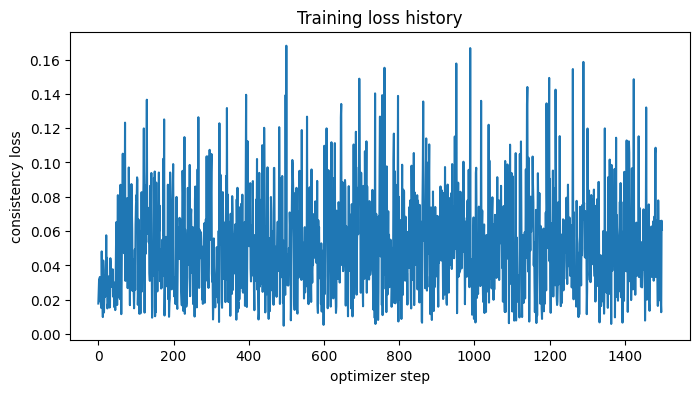

In [45]:
if os.path.isdir(os.path.join(cfg.CHECKPOINT_DIR, "final_lora_adapter")):
    _val_loss = evaluate_val_loss(max_batches=50)
    print(f"Validation loss (trained adapter, {min(50, len(val_dataset))} held-out batches): {_val_loss:.5f}")
else:
    print("No trained adapter found yet — run training (Section 16) first. "
          "Skipping validation-loss evaluation for now.")

if 'loss_history' in dir() and loss_history:
    plt.figure(figsize=(8, 4))
    plt.plot(loss_history)
    plt.xlabel("optimizer step"); plt.ylabel("consistency loss")
    plt.title("Training loss history")
    plt.show()
else:
    print("No loss_history in memory (training has not been run in this session).")

## 19. Teacher-versus-Student Evaluation

Compares the **teacher** (50-step DDIM explicitly configured from the training scheduler, `guidance_scale=7.5`) against the **trained student LoRA
adapter** at 1, 2, and 4 inference steps, on held-out prompts (drawn from `val_dataset`, which was
never used in training, plus independent hand-written prompts), with fixed seeds for reproducibility.

Student inference uses `diffusers.LCMScheduler` — the actual LCM sampling procedure (verified by a
unit test in Section 14 to produce exactly the requested step count) — **not** ordinary DDIM sampling
substituted in. Per the official script's own validation routine (`log_validation`), student inference
uses `guidance_scale=1.0`: CFG is distilled into the weights via the `w`-guided teacher target during
training, so a second separate CFG pass at inference would double up on guidance relative to what the
student was actually trained to approximate.

In [46]:
from diffusers import LCMScheduler

def load_trained_student(adapter_dir=None):
    """Build an inference pipeline that REUSES the already-loaded student, VAE and text encoder.

    The student UNet in this notebook already contains the trained `default` LoRA adapter in memory.
    This avoids loading a second complete SD 1.5 pipeline (which can OOM on a 16-GB T4).
    """
    adapter_dir = adapter_dir or os.path.join(cfg.CHECKPOINT_DIR, "final_lora_adapter")
    assert os.path.isdir(adapter_dir), (
        f"No exported adapter at {adapter_dir}. Complete training and adapter export first."
    )
    global _STUDENT_TRAINED_IN_MEMORY
    if not _STUDENT_TRAINED_IN_MEMORY:
        # Fresh kernel: replace the randomly initialized adapter with the exported trained adapter.
        if not hasattr(student_unet, "load_lora_adapter"):
            raise RuntimeError("This Diffusers UNet does not expose load_lora_adapter().")
        student_unet.load_lora_adapter(
            adapter_dir, weight_name="pytorch_lora_weights.safetensors",
            adapter_name="trained_export", prefix=None
        )
        student_unet.set_adapter("trained_export")
        _STUDENT_TRAINED_IN_MEMORY = True

    student_unet.eval()
    eval_scheduler = LCMScheduler.from_config(pipe.scheduler.config)
    eval_pipe = StableDiffusionPipeline(
        vae=vae,
        text_encoder=text_encoder,
        tokenizer=tokenizer,
        unet=student_unet,
        scheduler=eval_scheduler,
        safety_checker=None,
        feature_extractor=None,
        requires_safety_checker=False,
    )
    # Components are shared with the already-loaded models; no duplicate .from_pretrained() call.
    return eval_pipe

def generate(pipe_obj, prompt, steps, seed, guidance_scale):
    generator = torch.Generator(device="cuda").manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.synchronize()
    t0 = time.perf_counter()
    out = pipe_obj(
        prompt=prompt,
        num_inference_steps=steps,
        guidance_scale=guidance_scale,
        generator=generator,
    )
    if torch.cuda.is_available():
        torch.cuda.synchronize()
    elapsed = time.perf_counter() - t0
    return out.images[0], elapsed

print("Evaluation pipeline builder defined: reuses existing student/VAE/text encoder to reduce VRAM.")

Evaluation pipeline builder defined: reuses existing student/VAE/text encoder to reduce VRAM.


The config attributes {'skip_prk_steps': True} were passed to LCMScheduler, but are not expected and will be ignored. Please verify your scheduler_config.json configuration file.


  0%|          | 0/50 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/2 [00:00<?, ?it/s]

  0%|          | 0/4 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

... (7 outputs left out)

  0%|          | 0/50 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/2 [00:00<?, ?it/s]

  0%|          | 0/4 [00:00<?, ?it/s]

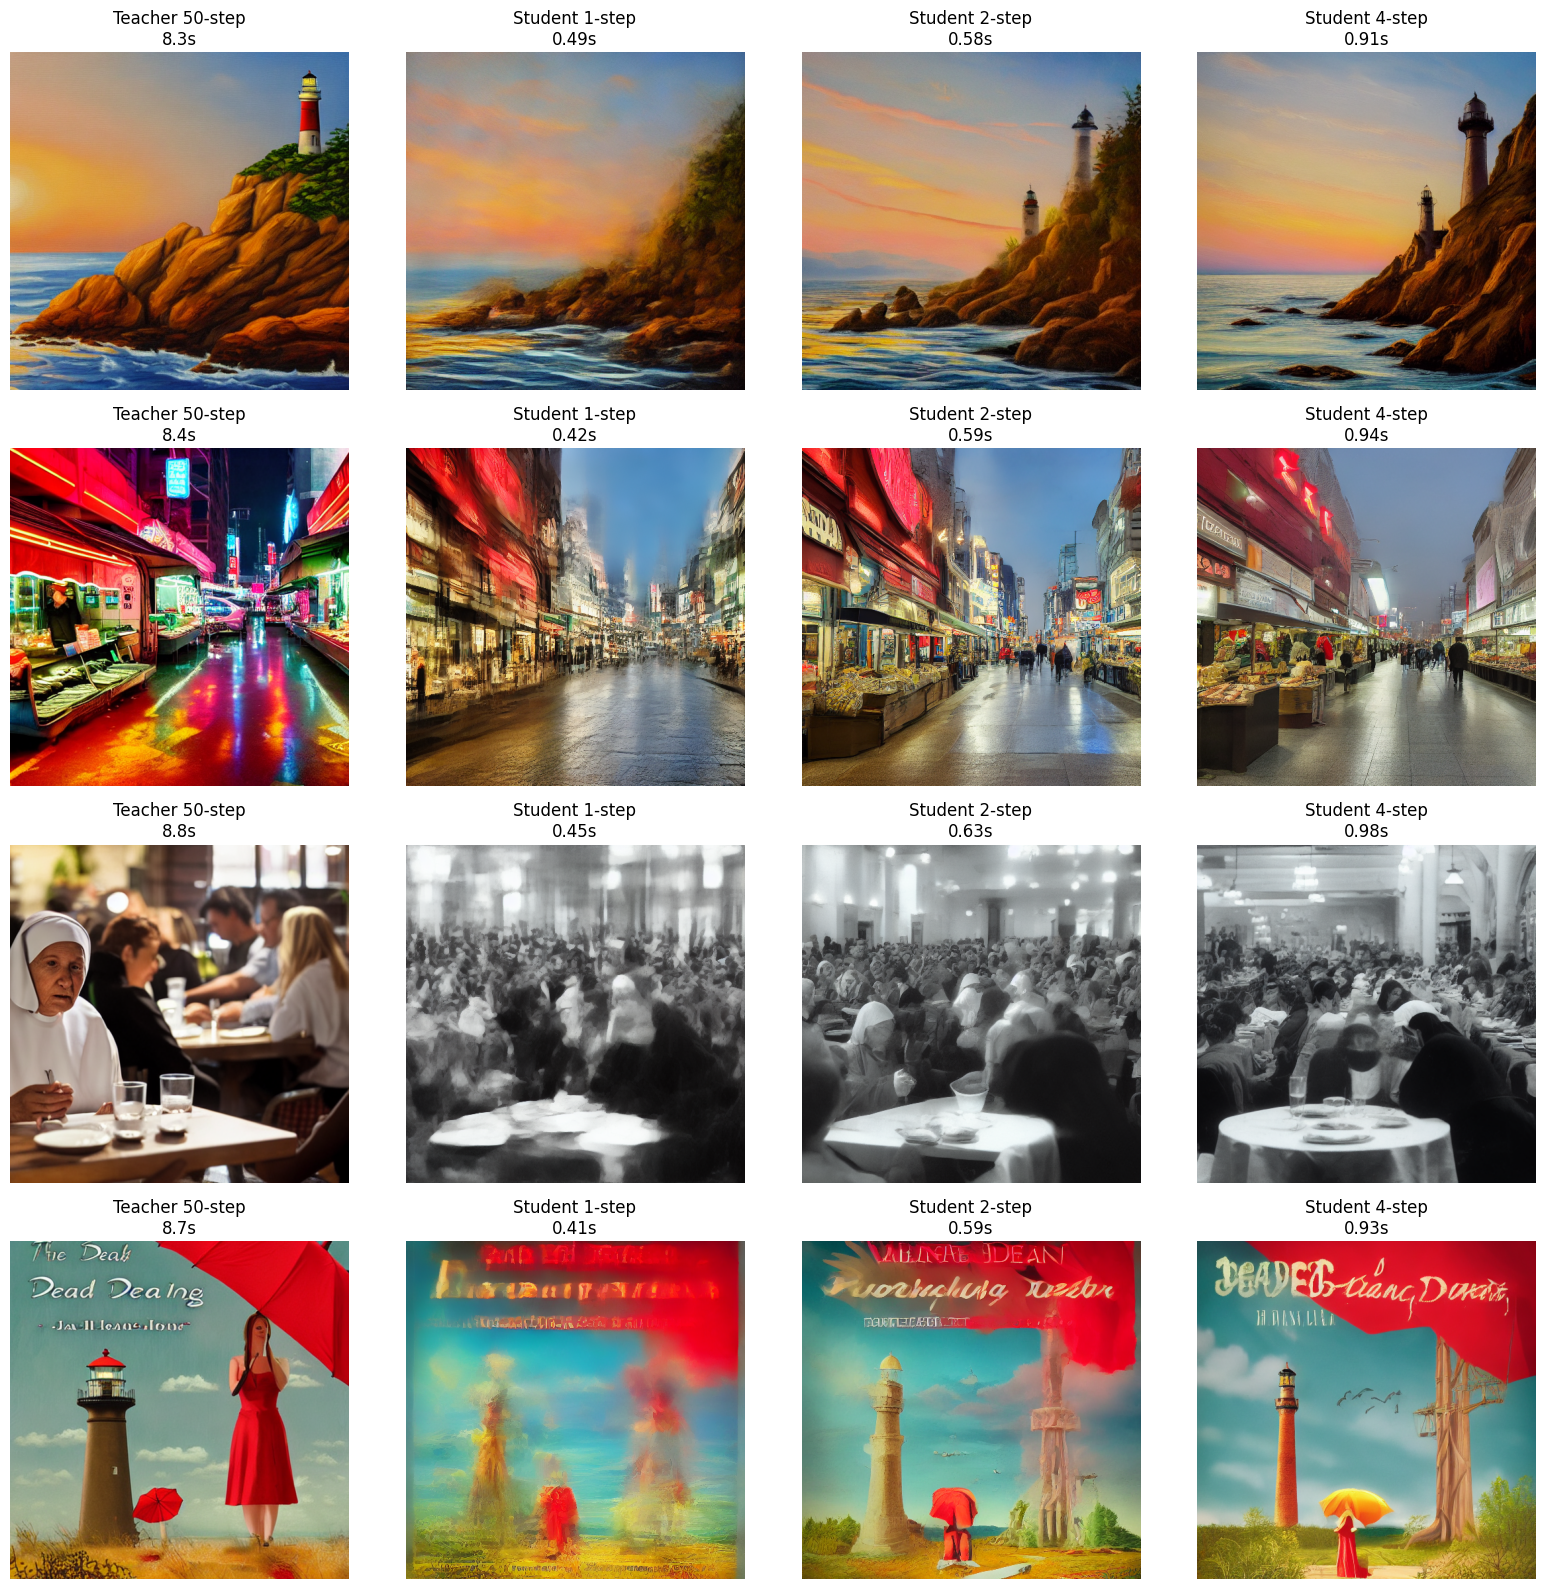

,prompt,seed,model,steps,time_s
0,"A lighthouse on a rocky coast at sunset, oil p...",42,teacher,50,8.344382
1,"A lighthouse on a rocky coast at sunset, oil p...",42,student,1,0.488651
2,"A lighthouse on a rocky coast at sunset, oil p...",42,student,2,0.576570
3,"A lighthouse on a rocky coast at sunset, oil p...",42,student,4,0.910318
4,"A futuristic city street market at night, neon...",43,teacher,50,8.376656
5,"A futuristic city street market at night, neon...",43,student,1,0.419485
6,"A futuristic city street market at night, neon...",43,student,2,0.586063
7,"A futuristic city street market at night, neon...",43,student,4,0.936654
8,"A Nun eating at a table, in a crowded restaurant.",44,teacher,50,8.790429
9,"A Nun eating at a table, in a crowded restaurant.",44,student,1,0.452069


In [47]:
if os.path.isdir(os.path.join(cfg.CHECKPOINT_DIR, "final_lora_adapter")):
    held_out_prompts = [
        "A lighthouse on a rocky coast at sunset, oil painting style",
        "A futuristic city street market at night, neon signs, rain-slicked pavement",
    ]
    for i in range(min(2, len(val_dataset))):
        held_out_prompts.append(val_dataset[i]["caption"])

    eval_pipe = load_trained_student()
    records = []
    fig, axes = plt.subplots(len(held_out_prompts), 4, figsize=(16, 4 * len(held_out_prompts)))
    if len(held_out_prompts) == 1:
        axes = axes[None, :]

    for row, prompt in enumerate(held_out_prompts):
        seed = cfg.RANDOM_SEED + row
        teacher_img, teacher_t = generate(pipe, prompt, steps=50, seed=seed, guidance_scale=7.5)
        axes[row, 0].imshow(teacher_img); axes[row, 0].set_title(f"Teacher 50-step\n{teacher_t:.1f}s"); axes[row, 0].axis("off")
        records.append({"prompt": prompt, "seed": seed, "model": "teacher", "steps": 50, "time_s": teacher_t})

        for col, n_steps in enumerate([1, 2, 4], start=1):
            img, t = generate(eval_pipe, prompt, steps=n_steps, seed=seed, guidance_scale=1.0)
            axes[row, col].imshow(img); axes[row, col].set_title(f"Student {n_steps}-step\n{t:.2f}s"); axes[row, col].axis("off")
            records.append({"prompt": prompt, "seed": seed, "model": "student", "steps": n_steps, "time_s": t})

    plt.tight_layout(); plt.show()
    import pandas as pd
    display(pd.DataFrame(records))
else:
    print("No trained adapter found — run training (Section 16) first, then re-run this cell.")

**Adapter round-trip check:** loads the exported adapter into a fresh UNet and compares every tensor with the in-memory student. Expect `[PASS]` with a tiny max difference.

In [48]:
import os, torch
from diffusers import UNet2DConditionModel
from peft.utils import get_peft_model_state_dict

adapter_dir = os.path.join(cfg.CHECKPOINT_DIR, "final_lora_adapter")
fresh_unet = UNet2DConditionModel.from_pretrained(cfg.MODEL_ID, subfolder="unet", torch_dtype=torch.float16)
fresh_unet.load_lora_adapter(adapter_dir, weight_name="pytorch_lora_weights.safetensors", adapter_name="roundtrip", prefix=None)

expected = get_peft_model_state_dict(student_unet, adapter_name="default")
actual = get_peft_model_state_dict(fresh_unet, adapter_name="roundtrip")
print("keys expected/actual:", len(expected), len(actual), "| same keys:", set(expected) == set(actual))

max_diff = 0.0
for k in expected:
    d = (expected[k].detach().cpu().float() - actual[k].detach().cpu().float()).abs().max().item()
    max_diff = max(max_diff, d)
print("max abs difference across all tensors:", max_diff)
print("[PASS]" if set(expected) == set(actual) and max_diff < 1e-3 else "[CHECK]")
del fresh_unet

keys expected/actual: 556 556 | same keys: True
max abs difference across all tensors: 3.0517578125e-05
[PASS]


**Read the images, not just the numbers.** A low training or validation loss is necessary but not sufficient evidence of good 1-4 step samples — judge the generated grid directly, and remember a small training dataset limits how far the student can generalize beyond the training distribution.

## 20. CLIP Benchmark (same method as v1)

Judge: `openai/clip-vit-base-patch32`. Score = cosine similarity of image and text embeddings x 100.
Wrong-prompt baseline = the prompt list shifted by one. Seed for prompt `i` is `100 + i`.
Teacher: 50-step DDIM, guidance 7.5. Student: `LCMScheduler`, guidance 1.0, at 1, 2 and 4 steps.
One warm-up generation before timing, and `torch.cuda.synchronize()` around every timed call (inside `generate`).
Set `RUN_TEACHER = False` to skip the teacher (about 3 minutes) and reuse v1's teacher row, since the teacher, prompts and seeds are identical.

Caveats for any write-up: 20 prompts and one seed each means differences under about 1 CLIP point are noise; CLIP measures prompt match, not sharpness or artifacts; speedups apply only to this T4, 512x512 and this pipeline.

In [49]:
import pandas as pd
from transformers import CLIPModel, CLIPProcessor

BENCH_TAG = "r64_step1500"     # change to match the checkpoint you are evaluating, e.g. "r64_step3000"
RUN_TEACHER = True

BENCH_PROMPTS = [
    "A golden retriever running on a beach at sunrise",
    "A bowl of fresh fruit on a wooden table, natural light",
    "A snow-covered mountain village at dusk",
    "A red vintage car parked on a cobblestone street",
    "A child flying a kite in a green field",
    "A cup of coffee on a cafe table next to a window",
    "A sailboat on a calm blue lake with mountains behind",
    "A busy train station with people walking, morning light",
    "A cat sleeping on a sofa near a sunny window",
    "A chef cooking in a modern kitchen",
    "A bicycle leaning against a brick wall covered in ivy",
    "A group of friends having a picnic in a park",
    "A tall waterfall in a lush green forest",
    "A street musician playing guitar on a city sidewalk",
    "A white horse galloping across an open meadow",
    "A skateboarder doing a trick at a skate park",
    "A fishing boat in a harbor at sunset",
    "A farmer harvesting wheat in a golden field",
    "A rainy city street at night with umbrellas",
    "A hot air balloon floating over a valley at dawn",
]
assert len(BENCH_PROMPTS) == 20

clip_id = "openai/clip-vit-base-patch32"
clip_model = CLIPModel.from_pretrained(clip_id).to("cuda").eval()
clip_proc = CLIPProcessor.from_pretrained(clip_id)

@torch.no_grad()
def clip_scores(images, texts):
    inp = clip_proc(text=texts, images=images, return_tensors="pt", padding=True, truncation=True).to("cuda")
    img = clip_model.get_image_features(pixel_values=inp["pixel_values"])
    txt = clip_model.get_text_features(input_ids=inp["input_ids"], attention_mask=inp["attention_mask"])
    img = img / img.norm(dim=-1, keepdim=True)
    txt = txt / txt.norm(dim=-1, keepdim=True)
    return (img * txt).sum(-1).float().cpu().numpy() * 100.0

def run_setup(label, pipe_obj, steps, guidance):
    generate(pipe_obj, BENCH_PROMPTS[0], steps, 0, guidance)           # warm-up, not timed
    imgs, times = [], []
    for i, p in enumerate(BENCH_PROMPTS):
        img, t = generate(pipe_obj, p, steps, 100 + i, guidance)
        imgs.append(img); times.append(t)
    matched = clip_scores(imgs, BENCH_PROMPTS).mean()
    wrong = clip_scores(imgs, BENCH_PROMPTS[1:] + BENCH_PROMPTS[:1]).mean()
    print(f"{label}: matched={matched:.2f} wrong={wrong:.2f} mean_time={np.mean(times):.3f}s")
    return {"setup": label, "clip_score_matched": round(float(matched), 2),
            "clip_score_wrong_prompt": round(float(wrong), 2), "mean_time_s": round(float(np.mean(times)), 3)}

bench_rows = []
if RUN_TEACHER:
    bench_rows.append(run_setup("Teacher 50-step", pipe, 50, 7.5))

eval_pipe = load_trained_student()
for n in (1, 2, 4):
    bench_rows.append(run_setup(f"Student {n}-step", eval_pipe, n, 1.0))

bench_df = pd.DataFrame(bench_rows)
if RUN_TEACHER:
    bench_df["speedup_vs_teacher"] = (bench_df["mean_time_s"].iloc[0] / bench_df["mean_time_s"]).round(1)
display(bench_df)

bench_path = os.path.join(cfg.CHECKPOINT_DIR, f"clip_benchmark_{BENCH_TAG}.csv")
bench_df.to_csv(bench_path, index=False)
print("saved:", bench_path)

config.json: 0.00B [00:00, ?B/s]

pytorch_model.bin:   0%|          | 0.00/605M [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/605M [00:00<?, ?B/s]

Using a slow image processor as `use_fast` is unset and a slow processor was saved with this model. `use_fast=True` will be the default behavior in v4.52, even if the model was saved with a slow processor. This will result in minor differences in outputs. You'll still be able to use a slow processor with `use_fast=False`.


preprocessor_config.json:   0%|          | 0.00/316 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/592 [00:00<?, ?B/s]

... (91 outputs left out)

  0%|          | 0/4 [00:00<?, ?it/s]

Student 4-step: matched=31.41 wrong=12.95 mean_time=0.938s


,setup,clip_score_matched,clip_score_wrong_prompt,mean_time_s,speedup_vs_teacher
0,Teacher 50-step,32.72,12.54,8.355,1.0
1,Student 1-step,29.67,14.67,0.408,20.5
2,Student 2-step,30.85,13.25,0.590,14.2
3,Student 4-step,31.41,12.95,0.938,8.9


saved: /content/drive/MyDrive/lcm_checkpoints_r64/clip_benchmark_r64_step1500.csv


In [50]:
import os, pandas as pd
out = os.path.join(cfg.CHECKPOINT_DIR, "results_r64_step1500")
os.makedirs(out, exist_ok=True)
fig.savefig(os.path.join(out, "grid_teacher_vs_student.png"), dpi=130, bbox_inches="tight")
pd.DataFrame(records).to_csv(os.path.join(out, "grid_timings.csv"), index=False)
with open(os.path.join(out, "prompts.txt"), "w") as f:
    f.write("\n".join(f"seed {cfg.RANDOM_SEED+i}: {p}" for i, p in enumerate(held_out_prompts)))
if "loss_history" in globals() and loss_history:
    pd.Series(loss_history, name="loss").to_csv(os.path.join(out, "loss_history.csv"), index_label="step")
ad = os.path.join(cfg.CHECKPOINT_DIR, "final_lora_adapter")
print("saved:", os.listdir(out))
print("adapter files:", os.listdir(ad), "| MB:", round(sum(os.path.getsize(os.path.join(ad, f)) for f in os.listdir(ad))/1e6, 1))

saved: ['grid_teacher_vs_student.png', 'grid_timings.csv', 'prompts.txt', 'loss_history.csv']
adapter files: ['pytorch_lora_weights.safetensors'] | MB: 269.1


## 21. Notes and Caveats

This notebook is an independent Colab-oriented implementation of SD 1.5 LCM-LoRA consistency distillation. The official LCM training script was used as the reference for the objective and scheduler mathematics. It does not claim a new distillation algorithm.

### Implementation details worth knowing
- Boundary-condition scaling uses `timestep * 10.0`, numerically identical to the official `/ 0.1` form.
- Teacher evaluation uses DDIM explicitly, not the pipeline's default scheduler. Student evaluation uses `LCMScheduler` at guidance 1.0.
- Text embeddings are cast to FP32; frozen weights are FP16; LoRA parameters are FP32.
- Checkpoints hold LoRA weights, optimizer, LR-scheduler and GradScaler state, loss history and RNG states, and are written atomically. The exported adapter (`final_lora_adapter/pytorch_lora_weights.safetensors`) holds the LoRA weights only.

### Things to avoid
- Every training run overwrites `<CHECKPOINT_DIR>/final_lora_adapter`. Keep `CHECKPOINT_DIR` pointed at `lcm_checkpoints_r64` for v2, and never at v1's folder.
- Do not load the adapter with `pipe.load_lora_weights(...)`: it silently loads nothing because the saved keys have no `unet.` prefix. Use `pipe.unet.load_lora_adapter(dir, weight_name="pytorch_lora_weights.safetensors", adapter_name="lcm", prefix=None)` followed by `pipe.unet.set_adapter("lcm")`.
- `pipe.unet.active_adapters` is a method: call it with parentheses.
- Training loss is noisy and validation loss showed no clear trend in v1, so judge quality by the image grid and CLIP, not by loss.
- Each rank-64 checkpoint is about 800 MB. Delete old `lcm_lora_step_*.pt` files from Drive as you go (keep the newest).

### Reporting
Name the datasets actually used (text-to-image-2M subset and Flickr30k subset), report only what the benchmark shows, and say plainly if v2 does not beat v1.